# Benchmark de obstrução: ViDDAR com diferentes VLMs

Este notebook roda a detecção de **ataques de obstrução** do ViDDAR (Xiu et al., IEEE TVCG 2025, §3.1,
§4.1 e §5.1) com os mesmos VLMs do benchmark de manipulação, sem mudar nada no pipeline replicado. A
pergunta é **como a escolha do VLM afeta o detector** e, em especial, **de onde vêm os falsos
positivos**.

**A tarefa.** Cada amostra é um par (imagem crua I_r, imagem aumentada I_a). Há obstrução quando o
conteúdo virtual cobre um objeto real importante, o *objeto-chave* (placa, extintor, tomada...). São 306
amostras de 23 classes de objeto, 145 obstruídas (rótulo 1) e 161 não obstruídas (rótulo 0).

**O pipeline do ViDDAR** (o mesmo da replicação, com os prompts literais do artigo):
1. o VLM recebe I_r e nomeia o objeto-chave;
2. o Grounding DINO localiza esse nome em I_r e o SAM recorta a máscara do objeto, m_k;
3. a máscara do conteúdo virtual, m_c, vem da diferença de pixels entre I_r e I_a;
4. há obstrução se |m_k ∩ m_c| / |m_k| ≥ α, com α = 0,25 (Eq. 4).

O VLM só participa do passo 1. O resto é geometria, e é isso que o artigo argumenta: separar o
reconhecimento (VLM) da decisão (geometria) é mais confiável que perguntar ao VLM se há obstrução.

## Métodos (Tabela 1 do artigo)

| Método | O que faz | Usa VLM |
|---|---|---|
| `viddar` | o pipeline acima | sim, só no passo 1 |
| `end_to_end` | o VLM nomeia o objeto e decide sozinho se ele está obstruído (vê I_r e I_a) | sim, decide tudo |
| `underdetailed` | como o ViDDAR, com um prompt mínimo para o objeto-chave | sim |
| `greedy` | o VLM lista vários objetos; há obstrução se qualquer um passar de α | sim |
| `prior` | o detector recebe o **nome verdadeiro** do objeto: limite superior do pipeline | não |
| `saliency`, `canny` | linhas de base clássicas de visão computacional | não |

Os três métodos sem VLM não dependem do modelo: rodam uma vez e servem de referência.

## Roteiro

| Seção | O que mostra |
|---|---|
| 2 | configuração |
| 3 | execução (só roda o que ainda não existe em `results/`) |
| **4** | **resultado geral por modelo e método (Tabela 1), ViDDAR × end-to-end, comparação entre modelos e entre prompts do objeto-chave** |
| **5** | **análise dos erros: em que etapa do pipeline cada FP e FN acontece** |
| 6 | sensibilidade ao limiar α |
| 7 | interpretação e resumo |
| **8** | **conclusão** |

## Convenções

- **Reconhecimento do objeto-chave**, dois critérios:
  - **léxico:** a frase do VLM nomeia a classe certa (permissivo: "black tv stand" conta como TV);
  - **com máscara (IoU ≥ 0,5):** a máscara recortada a partir da frase cobre o objeto verdadeiro. É o
    critério mais confiável para conclusões.
- **mIoU:** IoU médio entre a máscara do objeto prevista e a verdadeira.
- **Acurácia** = acertos / 306. **Precisão** = obstruções reais entre as amostras marcadas.
  **Recall** = obstruções detectadas / 145. **FPR** = não obstruídas marcadas / 161. **FNR** = 1 − recall.
- Resposta sem sim/não (só no `end_to_end`) conta como erro.
- **McNemar:** teste pareado sobre as mesmas 306 amostras; uma diferença só conta com p < 0,05.

## Antes de começar

- Use o kernel **"Python (ViDDAR .venv)"** e rode as células em ordem.
- A lógica fica em `viddar/`; a mesma execução roda pela linha de comando com
  `scripts/run_obstruction.py --methods viddar end_to_end underdetailed greedy --vlm <modelo>`.
- As respostas do VLM ficam em cache (`results/cache/`): execuções prontas só são relidas.

## 1. Ambiente

In [1]:
import os
import sys
from pathlib import Path

# O notebook pode ser aberto a partir da raiz ou da pasta notebooks/.
ROOT = Path.cwd() if (Path.cwd() / "viddar").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from viddar import obstruction, reporting, viz
from viddar.experiments import ObstructionConfig, load_run, run_obstruction

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 250)
print("raiz do repositório:", ROOT)

raiz do repositório: C:\Users\lucas\Desktop\mestrado\vr_va\ViDDAR-Dataset


## 2. Configuração

- **`MODELS`:** os mesmos presets do benchmark de manipulação (`viddar/vlm.py`).
- **`METHODS`:** métodos com VLM, rodados para cada modelo. **`BASELINES`:** métodos sem VLM, rodados
  uma vez (pasta `results/obstruction/no_vlm/`).
- **`ALPHA`:** limiar da Eq. 4 (artigo: 0,25).
- **`RUN_MISSING`:** com `True`, executa o que ainda não existe; com `False`, só lê `results/`.
- **`LIMIT`:** número de amostras, para testes rápidos. Grava em `results/_smoke`; apague a pasta depois.

In [2]:
MODELS = ["qwen3-vl-2b", "qwen3-vl-4b", "qwen3-vl-8b-4bit", "llava-next-8b-4bit", "gemma4-12b-4bit"]
METHODS = ["viddar", "end_to_end", "underdetailed", "greedy"]
BASELINES = ["prior", "saliency", "canny"]
ALPHA = 0.25

RUN_MISSING = True   # executa o que ainda não existe
LIMIT = None         # None = dataset completo; ex.: 5 para teste rápido

MANIFEST = "data/manifests/viddar_obstruction.csv"
OUT_ROOT = Path("results" if LIMIT is None else "results/_smoke")
print("resultados em:", OUT_ROOT)

resultados em: results


## 3. Execução

Para cada modelo, roda os métodos de `METHODS` que ainda não têm `metrics.json`, em estágios: primeiro
todas as chamadas ao VLM, depois o modelo é descarregado e entram o Grounding DINO e o SAM (um modelo
por vez na GPU). Os métodos sem VLM rodam uma vez. Com o dataset completo, cada modelo novo leva cerca de
1 a 3 h, conforme o tamanho; o `viddar` e o `end_to_end` compartilham a pergunta do objeto-chave pelo
cache.

In [3]:
def missing(model_dir: str, methods: list[str]) -> list[str]:
    return [m for m in methods if not (OUT_ROOT / "obstruction" / model_dir / m / "metrics.json").exists()]


todo = {model: missing(model, METHODS) for model in MODELS}
todo["no_vlm"] = missing("no_vlm", BASELINES)
for model, methods in todo.items():
    if not methods:
        continue
    if not RUN_MISSING:
        print("falta:", model, methods)
        continue
    print("executando:", model, methods)
    run_obstruction(ObstructionConfig(manifest=MANIFEST, methods=methods,
                                      vlm=MODELS[0] if model == "no_vlm" else model, alpha=ALPHA,
                                      limit=LIMIT, out=str(OUT_ROOT / "obstruction")))

runs = reporting.load_obstruction_runs(OUT_ROOT, MODELS, METHODS, BASELINES)
print(f"{len(runs)} execuções carregadas:", sorted(f"{m}/{k}" for m, k in runs))

23 execuções carregadas: ['gemma4-12b-4bit/end_to_end', 'gemma4-12b-4bit/greedy', 'gemma4-12b-4bit/underdetailed', 'gemma4-12b-4bit/viddar', 'llava-next-8b-4bit/end_to_end', 'llava-next-8b-4bit/greedy', 'llava-next-8b-4bit/underdetailed', 'llava-next-8b-4bit/viddar', 'no_vlm/canny', 'no_vlm/prior', 'no_vlm/saliency', 'qwen3-vl-2b/end_to_end', 'qwen3-vl-2b/greedy', 'qwen3-vl-2b/underdetailed', 'qwen3-vl-2b/viddar', 'qwen3-vl-4b/end_to_end', 'qwen3-vl-4b/greedy', 'qwen3-vl-4b/underdetailed', 'qwen3-vl-4b/viddar', 'qwen3-vl-8b-4bit/end_to_end', 'qwen3-vl-8b-4bit/greedy', 'qwen3-vl-8b-4bit/underdetailed', 'qwen3-vl-8b-4bit/viddar']


## 4. Resultado geral (Tabela 1 do artigo)

Uma linha por modelo e método, com as métricas da Tabela 1 (reconhecimento do objeto-chave, mIoU e
acurácia) e também precisão, recall, FPR e FNR. As linhas `no_vlm` são as referências sem VLM. Os
números do artigo vêm logo abaixo.

In [4]:
bench = reporting.obstruction_benchmark(runs)
order = {m: i for i, m in enumerate(MODELS + [reporting.NO_VLM])}
bench = bench.sort_values(["método", "modelo"], key=lambda s: s.map(order) if s.name == "modelo"
                          else s.map({m: i for i, m in enumerate(METHODS + BASELINES)}))
display(bench.reset_index(drop=True))
display(Markdown("**Referência: Tabela 1 do artigo** (em %)"))
display(reporting.PAPER_TABLE1)

,modelo,método,objeto-chave (léxico),"objeto-chave (IoU ≥ 0,5)",mIoU,acurácia,acurácia IC95,precisão,recall,FPR,FNR,FP,FN,sem resposta
0,qwen3-vl-2b,viddar,65.7,72.5,66.2,84.6,"[80.2, 88.2]",90.8,75.2,6.8,24.8,11,36,0
1,qwen3-vl-4b,viddar,83.0,89.9,80.6,91.5,"[87.8, 94.1]",95.4,86.2,3.7,13.8,6,20,0
2,qwen3-vl-8b-4bit,viddar,80.4,85.0,77.1,91.8,"[88.2, 94.4]",97.6,84.8,1.9,15.2,3,22,0
3,llava-next-8b-4bit,viddar,70.3,76.1,68.8,88.2,"[84.1, 91.4]",91.6,82.8,6.8,17.2,11,25,0
4,gemma4-12b-4bit,viddar,80.7,88.6,80.6,90.5,"[86.7, 93.3]",97.5,82.1,1.9,17.9,3,26,0
5,qwen3-vl-2b,end_to_end,65.7,NaN,NaN,45.1,"[39.6, 50.7]",45.6,81.4,87.6,18.6,141,27,0
6,qwen3-vl-4b,end_to_end,83.0,NaN,NaN,72.9,"[67.6, 77.6]",73.5,66.9,21.7,33.1,35,48,0
7,qwen3-vl-8b-4bit,end_to_end,80.4,NaN,NaN,73.5,"[68.3, 78.2]",67.6,84.8,36.6,15.2,59,22,0
8,llava-next-8b-4bit,end_to_end,70.3,NaN,NaN,51.3,"[45.7, 56.9]",42.9,8.3,9.9,91.7,16,133,0
9,gemma4-12b-4bit,end_to_end,80.7,NaN,NaN,81.7,"[77.0, 85.6]",80.7,80.7,17.4,19.3,28,28,0


**Referência: Tabela 1 do artigo** (em %)

,method,vlm,key_obj_acc,mIoU,accuracy
0,viddar,GPT-4o (paper),91.83,72.15,92.15
1,viddar,LLaVA-Next-8b (paper),85.95,71.85,89.21
2,end_to_end,GPT-4o (paper),91.83,NaN,81.04
3,end_to_end,LLaVA-Next-8b (paper),85.95,NaN,55.23
4,underdetailed,GPT-4o (paper),86.60,70.21,86.92
5,underdetailed,LLaVA-Next-8b (paper),76.47,61.58,81.37
6,greedy,GPT-4o (paper),93.14,67.93,88.89
7,greedy,LLaVA-Next-8b (paper),88.89,64.84,85.62
8,saliency,- (paper),NaN,NaN,51.63
9,canny,- (paper),NaN,NaN,51.96


**Leitura (execução completa de 17/11/2026).**

- **Com o ViDDAR, todos os modelos ficam entre 84,6% e 91,8%.**
  - 4B (91,5%), 8B (91,8%) e Gemma (90,5%) chegam perto do GPT-4o do artigo (92,2%).
  - O LLaVA (88,2%) reproduz de perto o artigo (89,2%).
  - O teto é o `prior`, com o nome verdadeiro do objeto: 93,8%.
- **O detector erra mais por omissão do que por alarme falso.**
  - Precisão de 90,8% a 97,6% e FPR de 1,9% a 6,8%, contra FNR de 13,8% a 24,8%.
  - Em números absolutos: 3 FP no 8B e no Gemma, 6 no 4B e 11 no 2B e no LLaVA.
- **O reconhecimento do objeto-chave (IoU ≥ 0,5) acompanha a acurácia:**

  | Modelo | Reconhecimento | Acurácia (ViDDAR) |
  |---|---|---|
  | 4B | 89,9% | 91,5% |
  | Gemma | 88,6% | 90,5% |
  | 8B | 85,0% | 91,8% |
  | LLaVA | 76,1% | 88,2% |
  | 2B | 72,5% | 84,6% |

  O 8B reconhece menos objetos que o 4B e mesmo assim tem a mesma acurácia, porque erra menos nos
  pares não obstruídos.
- **O end-to-end varia muito mais: de 45,1% a 81,7%.** O LLaVA (51,3%) reproduz o artigo (55,2%), e o
  Gemma (81,7%) iguala o GPT-4o do artigo no end-to-end (81,0%).
- **As linhas de base clássicas ficam no acaso,** como no artigo: saliência 52,3%, Canny 49,7%.

### 4.1 ViDDAR × end-to-end

A comparação central do artigo: deixar a decisão com a geometria (ViDDAR) é melhor que perguntar ao
VLM se o objeto está obstruído (end-to-end)? O teste de McNemar compara os dois nas mesmas 306 amostras.

In [5]:
display(reporting.obstruction_vs(runs, MODELS, "viddar", "end_to_end"))

,modelo,acurácia viddar,acurácia end_to_end,só viddar acerta,só end_to_end acerta,McNemar p,viddar vs end_to_end
0,qwen3-vl-2b,84.6,45.1,152,31,0.000,melhorou
1,qwen3-vl-4b,91.5,72.9,74,17,0.000,melhorou
2,qwen3-vl-8b-4bit,91.8,73.5,68,12,0.000,melhorou
3,llava-next-8b-4bit,88.2,51.3,126,13,0.000,melhorou
4,gemma4-12b-4bit,90.5,81.7,43,16,0.001,melhorou


**Leitura.**

- **O ViDDAR supera o end-to-end em todos os modelos** (p ≤ 0,001).
- **A vantagem encolhe à medida que o VLM melhora:** 39,5 p.p. no 2B, 36,9 no LLaVA, 18,6 no 4B, 18,3 no
  8B e 8,8 no Gemma.
- **No end-to-end, cada modelo tem o próprio viés**, como na manipulação:

  | Modelo | Respostas "sim" | Consequência |
  |---|---|---|
  | 2B | 259 de 306 | FPR de 87,6% |
  | LLaVA | 28 de 306 | recall de 8,3% |
  | 8B | 182 de 306 | FPR de 36,6% |
  | 4B | 132 de 306 | FNR de 33,1% |

- **O Gemma é o único equilibrado:** responde "sim" em 145 de 306 amostras, exatamente o número de
  obstruídas, com FPR de 17,4% e FNR de 19,3%.

### 4.2 Comparação entre modelos

O teste de McNemar foi aplicado entre os modelos, nas mesmas 306 amostras, primeiro com o ViDDAR
(incluindo o `prior` como teto) e depois com o end-to-end.

In [6]:
display(Markdown("**ViDDAR (e o `prior`)**"))
display(reporting.pairwise_comparison(runs, [(m, "viddar") for m in MODELS if (m, "viddar") in runs]
                                      + [(reporting.NO_VLM, "prior")]))
display(Markdown("**End-to-end**"))
display(reporting.pairwise_comparison(runs, [(m, "end_to_end") for m in MODELS if (m, "end_to_end") in runs]))

**ViDDAR (e o `prior`)**

,execução 1,execução 2,acurácia 1,acurácia 2,só 1 acerta,só 2 acerta,McNemar p,resultado
0,qwen3-vl-2b / viddar,qwen3-vl-4b / viddar,84.6,91.5,6,27,0.000,2 melhor
1,qwen3-vl-2b / viddar,qwen3-vl-8b-4bit / viddar,84.6,91.8,4,26,0.000,2 melhor
2,qwen3-vl-2b / viddar,llava-next-8b-4bit / viddar,84.6,88.2,12,23,0.090,sem diferença significativa
3,qwen3-vl-2b / viddar,gemma4-12b-4bit / viddar,84.6,90.5,6,24,0.001,2 melhor
4,qwen3-vl-2b / viddar,no_vlm / prior,84.6,93.8,3,31,0.000,2 melhor
5,qwen3-vl-4b / viddar,qwen3-vl-8b-4bit / viddar,91.5,91.8,6,7,1.000,sem diferença significativa
6,qwen3-vl-4b / viddar,llava-next-8b-4bit / viddar,91.5,88.2,17,7,0.064,sem diferença significativa
7,qwen3-vl-4b / viddar,gemma4-12b-4bit / viddar,91.5,90.5,11,8,0.648,sem diferença significativa
8,qwen3-vl-4b / viddar,no_vlm / prior,91.5,93.8,2,9,0.065,sem diferença significativa
9,qwen3-vl-8b-4bit / viddar,llava-next-8b-4bit / viddar,91.8,88.2,19,8,0.052,sem diferença significativa


**End-to-end**

,execução 1,execução 2,acurácia 1,acurácia 2,só 1 acerta,só 2 acerta,McNemar p,resultado
0,qwen3-vl-2b / end_to_end,qwen3-vl-4b / end_to_end,45.1,72.9,33,118,0.000,2 melhor
1,qwen3-vl-2b / end_to_end,qwen3-vl-8b-4bit / end_to_end,45.1,73.5,20,107,0.000,2 melhor
2,qwen3-vl-2b / end_to_end,llava-next-8b-4bit / end_to_end,45.1,51.3,109,128,0.242,sem diferença significativa
3,qwen3-vl-2b / end_to_end,gemma4-12b-4bit / end_to_end,45.1,81.7,29,141,0.000,2 melhor
4,qwen3-vl-4b / end_to_end,qwen3-vl-8b-4bit / end_to_end,72.9,73.5,38,40,0.910,sem diferença significativa
5,qwen3-vl-4b / end_to_end,llava-next-8b-4bit / end_to_end,72.9,51.3,102,36,0.000,1 melhor
6,qwen3-vl-4b / end_to_end,gemma4-12b-4bit / end_to_end,72.9,81.7,28,55,0.004,2 melhor
7,qwen3-vl-8b-4bit / end_to_end,llava-next-8b-4bit / end_to_end,73.5,51.3,128,60,0.000,1 melhor
8,qwen3-vl-8b-4bit / end_to_end,gemma4-12b-4bit / end_to_end,73.5,81.7,23,48,0.004,2 melhor
9,llava-next-8b-4bit / end_to_end,gemma4-12b-4bit / end_to_end,51.3,81.7,30,123,0.000,2 melhor


**Leitura.**

- **ViDDAR:** 4B, 8B e Gemma empatam entre si (p ≥ 0,39).
  - O 4B e o 8B não se distinguem do `prior` (p = 0,065 e 0,146). Com eles, o reconhecimento do
    objeto-chave praticamente deixa de ser o gargalo.
  - O Gemma (p = 0,013) e o LLaVA (p = 0,001) ainda ficam abaixo do `prior`.
  - O 2B perde para o 4B, o 8B, o Gemma e o `prior`. Contra o LLaVA, a diferença não é significativa
    (p = 0,09).
- **End-to-end:**
  - o Gemma supera todos (p ≤ 0,004);
  - o 4B e o 8B empatam (p = 0,91);
  - o LLaVA e o 2B empatam no fim da tabela (p = 0,24).
- **O tamanho dentro da família Qwen ajuda até o 4B.** Do 2B para o 4B o salto é grande (+6,9 p.p. no
  ViDDAR); do 4B para o 8B não há ganho, nem no ViDDAR nem no end-to-end.

### 4.3 Prompts do objeto-chave: `greedy` e `underdetailed`

Os dois métodos testam o passo 1 do pipeline:

- **`greedy`:** o VLM lista vários objetos em vez de um.
- **`underdetailed`:** o prompt perde o papel de especialista, a menção a segurança e os exemplos.

A tabela compara cada um com o ViDDAR, no mesmo modelo. Em seguida vêm as frases mais frequentes do
`underdetailed`.

In [7]:
display(reporting.obstruction_vs(runs, MODELS, "viddar", "greedy"))
display(reporting.obstruction_vs(runs, MODELS, "viddar", "underdetailed"))
display(reporting.top_key_phrases(runs, MODELS, "underdetailed", n=5))

,modelo,acurácia viddar,acurácia greedy,só viddar acerta,só greedy acerta,McNemar p,viddar vs greedy
0,qwen3-vl-2b,84.6,88.9,4,17,0.007,piorou
1,qwen3-vl-4b,91.5,90.5,4,1,0.375,sem diferença significativa
2,qwen3-vl-8b-4bit,91.8,92.2,0,1,1.000,sem diferença significativa
3,llava-next-8b-4bit,88.2,87.3,8,5,0.581,sem diferença significativa
4,gemma4-12b-4bit,90.5,90.5,2,2,1.000,sem diferença significativa


,modelo,acurácia viddar,acurácia underdetailed,só viddar acerta,só underdetailed acerta,McNemar p,viddar vs underdetailed
0,qwen3-vl-2b,84.6,82.7,26,20,0.461,sem diferença significativa
1,qwen3-vl-4b,91.5,85.6,22,4,0.001,melhorou
2,qwen3-vl-8b-4bit,91.8,82.7,33,5,0.000,melhorou
3,llava-next-8b-4bit,88.2,82.7,29,12,0.012,melhorou
4,gemma4-12b-4bit,90.5,80.1,37,5,0.000,melhorou


,qwen3-vl-2b,qwen3-vl-4b,qwen3-vl-8b-4bit,llava-next-8b-4bit,gemma4-12b-4bit
1,door (27),fire extinguisher (21),fire extinguisher (22),fire extinguisher (22),door (29)
2,fire extinguisher (20),scissors (18),door (20),scissors (19),fire extinguisher (16)
3,scissors (18),fire hydrant (15),scissors (18),fire hydrant (16),scissors (16)
4,fire hydrant (15),toaster (13),exit sign (15),door (13),fire hydrant (14)
5,knife (15),stop sign (12),fire hydrant (15),coffee maker (13),knife (12)


**Leitura.**

- **O `greedy` empata com o ViDDAR em quase todos os modelos.** A exceção é o 2B, que melhora 4,3 p.p.
  (p = 0,007): listar vários objetos compensa a má escolha de um único, inclusive o "red box" copiado
  do prompt.
- **O `underdetailed` piora 4 dos 5 modelos:** 4B −5,9 p.p., 8B −9,1, LLaVA −5,5, Gemma −10,4. Só o 2B
  não muda. O artigo viu o mesmo com o GPT-4o (86,9% × 92,2%).
- **Sem a orientação de segurança, os modelos nomeiam objetos salientes, mas irrelevantes:** "door"
  aparece 29 vezes no Gemma, 27 no 2B e 20 no 8B. O Gemma é o mais afetado: o reconhecimento cai de
  88,6% para 62,1%.
- **O papel e os exemplos do prompt do artigo carregam informação útil.** O que eles dizem é *que tipo*
  de objeto importa, e é isso que define o objeto-chave.

## 5. Análise dos erros do ViDDAR

### 5.1 Em que etapa cada erro acontece

Cada erro do ViDDAR recebe a etapa do pipeline que falhou, nesta ordem:

1. **nada detectado:** o Grounding DINO não encontrou o objeto que o VLM nomeou. A razão fica 0, então
   só gera FN.
2. **objeto errado:** a máscara recortada não é o objeto-chave (IoU < 0,5 com a máscara verdadeira).
   Quase sempre o VLM nomeou outro objeto; às vezes o detector escolheu outro objeto com o mesmo nome.
3. **objeto certo, razão do lado errado de α:** o objeto certo foi recortado, mas a fração coberta pelo
   conteúdo ficou do outro lado do limiar, por máscara imprecisa ou por um rótulo perto do limite.

Cada célula traz "erros / amostras possíveis" (161 não obstruídas para FP, 145 obstruídas para FN). Entre
parênteses, quantas dessas mesmas amostras o `prior` também erra. O `prior` recebe o nome verdadeiro do
objeto, então:

- se ele **acerta**, o erro é do VLM (reconhecimento);
- se ele **também erra**, o problema está depois do VLM (detector, SAM, α ou o próprio rótulo).

In [8]:
display(reporting.obstruction_cause_comparison(runs, MODELS, "viddar"))
prior = runs.get((reporting.NO_VLM, "prior"))
if prior is not None:
    display(Markdown("**`prior` (nome verdadeiro do objeto), para comparação**"))
    display(obstruction.cause_table(prior))

,erro,causa,qwen3-vl-2b,qwen3-vl-4b,qwen3-vl-8b-4bit,llava-next-8b-4bit,gemma4-12b-4bit
0,FP,"objeto errado (IoU < 0,5)",11/161 (prior: 0),6/161 (prior: 0),3/161 (prior: 0),11/161 (prior: 0),3/161 (prior: 0)
1,FN,nada detectado,3/145 (prior: 0),0,0,0,0
2,FN,"objeto errado (IoU < 0,5)",17/145 (prior: 2),5/145 (prior: 3),7/145 (prior: 2),15/145 (prior: 6),12/145 (prior: 4)
3,FN,"objeto certo, razão do lado errado de α",16/145 (prior: 14),15/145 (prior: 14),15/145 (prior: 14),10/145 (prior: 9),14/145 (prior: 13)


**`prior` (nome verdadeiro do objeto), para comparação**

,error,cause,k,n
0,FP,wrong_object,1,161
1,FN,no_detection,1,145
2,FN,wrong_object,1,145
3,FN,threshold,16,145


**Leitura.**

**Todos os FP do ViDDAR são de reconhecimento.** Cada um é um "objeto errado" que o `prior` acerta. O
VLM nomeia outro objeto, e é esse objeto que o conteúdo virtual cobre. Os exemplos mostram que quase
sempre a cena tem mais de um objeto que merece atenção:

- **amostras de *warning sign*:** o 4B, o 8B e o LLaVA apontam a "black door with sign" (a porta onde a
  placa está) ou um "yellow safety bollard";
- **amostras de *boiling pot*:** o 8B, o LLaVA e o Gemma apontam o queimador ("glowing red burner", "hot
  stove burner", "black stove"), que também é um objeto de segurança;
- **no 2B,** 5 dos 11 FP vêm de "red box", copiado do prompt.

Os FP do ViDDAR surgem, portanto, em **cenas ambíguas**, em que o objeto-chave anotado não é o único
candidato razoável.

**Os FN têm duas origens:**

1. **Objeto certo, razão logo abaixo de α** (10 a 16 por modelo).
   - O `prior` também erra quase todos (9 a 14).
   - A razão desses casos fica entre 0,06 e 0,249, com mediana de cerca de 0,21: o conteúdo cobre um
     pouco menos de 25% do objeto.
   - 7 desses casos se repetem nos cinco modelos (6 deles também no `prior`). É um limite do limiar, da
     máscara m_c ou do rótulo, não do VLM.
2. **Objeto errado** (5 no 4B, até 17 no 2B).
   - A maior parte é erro do VLM.
   - Alguns são do detector. Exemplo: nas amostras de *traffic light*, todos os modelos dizem "red
     traffic light", mas o semáforo segmentado não é o anotado (IoU < 0,1, inclusive no `prior`).

### 5.2 Respostas mais frequentes do VLM

As cinco frases de objeto-chave mais comuns de cada modelo, com o número de ocorrências. O dataset tem
23 classes, então uma frase repetida dezenas de vezes que não corresponde às cenas indica que o modelo
copia o exemplo do prompt (o prompt do artigo cita "a red box").

In [9]:
display(reporting.top_key_phrases(runs, MODELS, "viddar", n=5))

,qwen3-vl-2b,qwen3-vl-4b,qwen3-vl-8b-4bit,llava-next-8b-4bit,gemma4-12b-4bit
1,red box (36),red fire extinguisher (21),red fire extinguisher (21),red fire extinguisher (23),red exit sign (17)
2,red fire extinguisher (24),red exit sign (20),red exit sign (20),scissors (14),yellow caution sign (13)
3,red exit sign (19),yellow caution sign (12),red stop sign (12),black stove (11),red stop sign (13)
4,black coffee maker (13),red stop sign (12),yellow wet floor sign (10),yellow caution sign (11),fire extinguisher (12)
5,biohazard sign (10),biohazard warning sign (9),yellow help station (10),black coffee maker (10),red fire extinguisher (12)


**Leitura.**

- **Só o Qwen3-VL-2B copia o exemplo do prompt:** "red box" aparece 36 vezes, e não existe essa classe no
  dataset.
- **As frases mais comuns dos outros modelos são classes reais,** em quantidade compatível com o dataset.
  Por exemplo, "red fire extinguisher" aparece 21 a 23 vezes, para 25 amostras de extintor.

### 5.3 Por classe de objeto

FPR do ViDDAR (%) por classe e modelo. As colunas `n` e `obstruídos` dão o tamanho de cada classe: com
poucas amostras, um único erro muda muito a taxa.

In [10]:
display(reporting.obstruction_by_group(runs, MODELS, "viddar", metric="fpr"))

,n,obstruídos,qwen3-vl-2b,qwen3-vl-4b,qwen3-vl-8b-4bit,llava-next-8b-4bit,gemma4-12b-4bit
group,,,,,,,
TV,5,3,50.0,50.0,0.0,0.0,0.0
boiling pot,10,4,16.7,0.0,16.7,16.7,16.7
caution sign,23,10,0.0,0.0,0.0,0.0,0.0
ceiling fan,8,4,0.0,0.0,0.0,25.0,0.0
coffee maker,14,9,0.0,0.0,0.0,0.0,0.0
electrical box,4,2,0.0,0.0,0.0,0.0,0.0
electrical outlet,29,12,11.8,0.0,0.0,0.0,11.8
electrical pot,11,6,0.0,0.0,0.0,0.0,0.0
exit sign,20,6,0.0,0.0,0.0,0.0,0.0


**Leitura.** Os FP se concentram em poucas classes, as mesmas cenas ambíguas da seção 5.1:

- ***warning sign*:** FP em 4 dos 5 modelos, chegando a 4 dos 8 não obstruídos no 4B e no LLaVA;
- ***boiling pot*:** FP em 4 dos 5 modelos;
- ***electrical outlet*:** FP no 2B e no Gemma.

Fora dessas três classes, 4B, 8B e Gemma têm só 2 FP, ambos no 4B (TV e *vehicle*). As classes são
pequenas (3 a 29 amostras), então as taxas por classe servem para localizar os casos, não para comparar
modelos.

### 5.4 Exemplos

Escolha um modelo e um tipo de erro. Verde: objeto-chave verdadeiro; laranja: conteúdo virtual. O
título mostra o que o VLM respondeu, a razão de obstrução e o IoU da máscara prevista.

qwen3-vl-4b: 6 FP {'FP:wrong_object': 6}


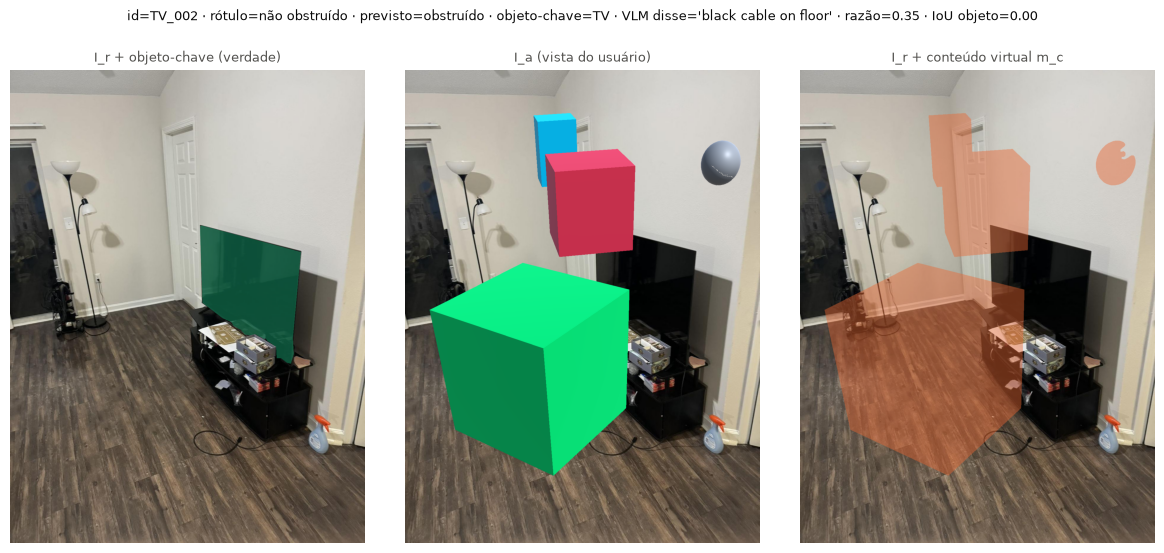

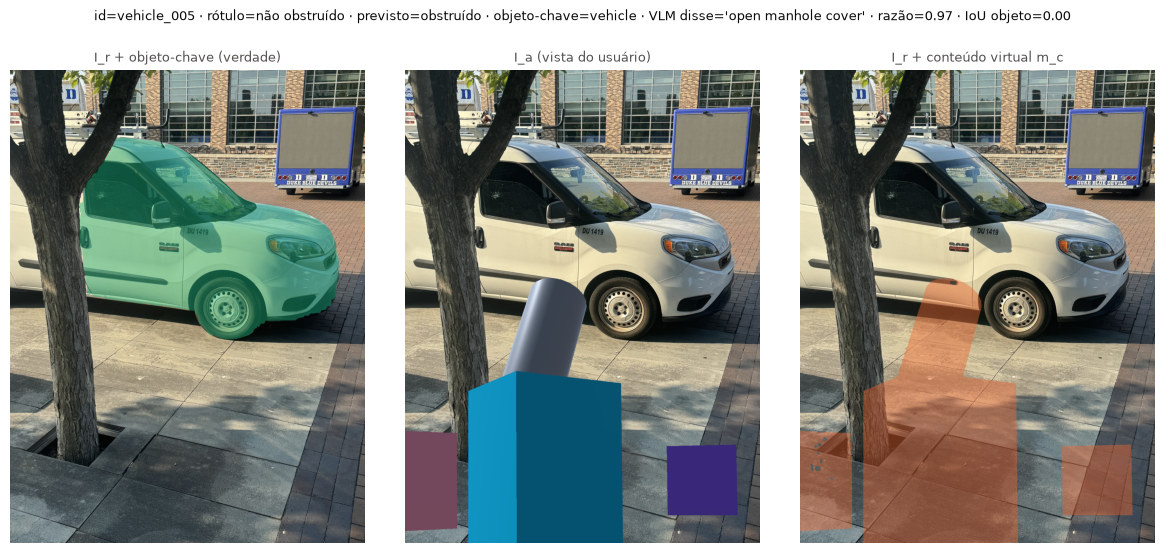

In [11]:
EX_MODEL, EX_ERROR, N_EXAMPLES = "qwen3-vl-4b", "FP", 2   # EX_ERROR: "FP" ou "FN"

run_dir = OUT_ROOT / "obstruction" / EX_MODEL / "viddar"
if (run_dir / "predictions.csv").exists():
    pred = load_run(run_dir, manifest=MANIFEST, kind="obstruction").predictions
    pred["cause"] = obstruction.error_causes(pred)
    sample = pred[pred["cause"].str.startswith(EX_ERROR)]
    print(f"{EX_MODEL}: {len(sample)} {EX_ERROR}", sample["cause"].value_counts().to_dict())
    for _, row in sample.head(N_EXAMPLES).iterrows():
        viz.show_obstruction(row)
        plt.show()

## 6. Sensibilidade ao limiar α

A razão |m_k ∩ m_c| / |m_k| fica salva por amostra, então a acurácia para qualquer α é recalculada sem
chamar o modelo. Uma linha por modelo (ViDDAR) e a do `prior` como referência. Se as curvas de todos os
modelos tiverem o pico no mesmo α, o limiar do artigo vale para qualquer VLM; a distância até a curva do
`prior` é o que se perde no reconhecimento do objeto.

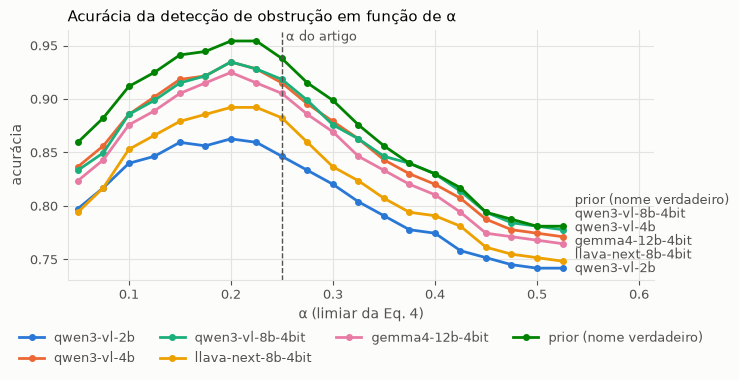

,qwen3-vl-2b,qwen3-vl-4b,qwen3-vl-8b-4bit,llava-next-8b-4bit,gemma4-12b-4bit,prior (nome verdadeiro)
alpha,,,,,,
0.050,79.7,83.7,83.3,79.4,82.4,85.9
0.075,81.7,85.6,85.0,81.7,84.3,88.2
0.100,84.0,88.6,88.6,85.3,87.6,91.2
0.125,84.6,90.2,89.9,86.6,88.9,92.5
0.150,85.9,91.8,91.5,87.9,90.5,94.1
0.175,85.6,92.2,92.2,88.6,91.5,94.4
0.200,86.3,93.5,93.5,89.2,92.5,95.4
0.225,85.9,92.8,92.8,89.2,91.5,95.4
0.250,84.6,91.5,91.8,88.2,90.5,93.8


In [12]:
curves = {model: runs[(model, "viddar")] for model in MODELS if (model, "viddar") in runs}
if prior is not None:
    curves["prior (nome verdadeiro)"] = prior
if curves:
    fig, sweep = viz.alpha_sweep(curves, paper_alpha=ALPHA)
    plt.show()
    display((sweep.set_index("alpha") * 100).round(1))

**Leitura.**

- **Todas as curvas têm o pico em α = 0,20,** inclusive a do `prior`: 2B 86,3%, 4B 93,5%, 8B 93,5%, LLaVA
  89,2%, Gemma 92,5%, `prior` 95,4%. O α = 0,25 do artigo fica um pouco acima do ótimo, para todos os
  modelos.
- **Isso é coerente com os FN de limiar da seção 5.1,** metade dos quais tem razão entre 0,20 e 0,25.
  Uma explicação provável é que as máscaras m_c, derivadas por diferença de pixels, são um pouco menores
  que as dos autores.
- **Escolher α = 0,20 aqui seria otimista,** porque ajusta o limiar no próprio conjunto de teste. Por
  isso mantemos 0,25, como no artigo.
- **A ordem dos modelos e a distância até o `prior` (cerca de 2 p.p. no 4B e no 8B) se mantêm em todos os
  α.** As conclusões não dependem do limiar.

## 7. Interpretação

- **A tese do artigo se mantém nos cinco modelos.**
  - O ViDDAR, que separa o reconhecimento (VLM) da decisão (geometria), supera o end-to-end com folga em
    todos (p ≤ 0,001).
  - Com o 4B, o 8B e o Gemma, a acurácia (90,5% a 91,8%) fica no nível do GPT-4o do artigo (92,2%). O 4B
    e o 8B não se distinguem estatisticamente do `prior`.
- **Os falsos positivos do ViDDAR são todos de reconhecimento e aparecem em cenas ambíguas.**
  - O VLM nomeia outro objeto plausível, que o conteúdo virtual cobre: a porta em vez da placa, o
    queimador em vez da panela.
  - O `prior`, que recebe o nome certo, tem só 1 FP em 161.
  - Melhorar a FPR passa pelo reconhecimento do objeto-chave, não pela geometria.
- **Os falsos negativos vêm, em sua maioria, de coberturas logo abaixo de α.** O `prior` também erra
  esses casos, então são um limite do limiar, da máscara ou do rótulo, não do VLM.
- **O prompt do objeto-chave importa:** sem a orientação de segurança (`underdetailed`), quatro modelos
  pioram de 5 a 10 p.p. Listar vários objetos (`greedy`) só ajuda o modelo mais fraco.
- **No end-to-end, cada modelo tem o próprio viés.**
  - O 2B diz "obstruído" quase sempre; o LLaVA quase nunca.
  - Só o Gemma é equilibrado (81,7%, no nível do GPT-4o do artigo).
- **O tamanho ajuda até certo ponto:** do 2B para o 4B o ganho é grande; do 4B para o 8B, não há ganho.
- **O contraste com a manipulação é o resultado mais informativo do benchmark.**
  - Os mesmos VLMs que não superam o detector trivial na manipulação, onde decidem sozinhos, chegam a
    ~91% na obstrução, onde só nomeiam um objeto e a geometria decide.
  - Na manipulação, os melhores resultados também vieram de tirar a decisão do VLM (regra A ∧ S ∧ I em
    código).

### Resumo

Uma linha por modelo com o ViDDAR e o end-to-end, e a distância até o `prior` (o que se perde no
reconhecimento do objeto-chave). Antes de concluir, leia algumas respostas brutas dos modelos novos
(seção 5.2 e `predictions.csv`).

In [13]:
rows = []
prior_acc = bench.loc[bench["método"] == "prior", "acurácia"]
prior_acc = float(prior_acc.iloc[0]) if len(prior_acc) else float("nan")
for model in MODELS:
    b = bench[bench["modelo"] == model].set_index("método")
    if "viddar" not in b.index:
        continue
    rows.append({"modelo": model,
                 "objeto-chave (IoU ≥ 0,5)": b.loc["viddar", "objeto-chave (IoU ≥ 0,5)"],
                 "ViDDAR: acurácia": b.loc["viddar", "acurácia"], "ViDDAR: FPR": b.loc["viddar", "FPR"],
                 "ViDDAR: FNR": b.loc["viddar", "FNR"],
                 "end-to-end: acurácia": b["acurácia"].get("end_to_end"),
                 "distância até o prior (p.p.)": round(prior_acc - b.loc["viddar", "acurácia"], 1)})
display(pd.DataFrame(rows))

,modelo,"objeto-chave (IoU ≥ 0,5)",ViDDAR: acurácia,ViDDAR: FPR,ViDDAR: FNR,end-to-end: acurácia,distância até o prior (p.p.)
0,qwen3-vl-2b,72.5,84.6,6.8,24.8,45.1,9.2
1,qwen3-vl-4b,89.9,91.5,3.7,13.8,72.9,2.3
2,qwen3-vl-8b-4bit,85.0,91.8,1.9,15.2,73.5,2.0
3,llava-next-8b-4bit,76.1,88.2,6.8,17.2,51.3,5.6
4,gemma4-12b-4bit,88.6,90.5,1.9,17.9,81.7,3.3


## 8. Conclusão

Execução completa de 17/11/2026: 5 VLMs × 4 métodos com VLM, mais 3 linhas de base sem VLM, sobre 306
amostras, com α = 0,25 e decodificação greedy.

### Principais achados

1. **O pipeline do ViDDAR é robusto à troca do VLM.**
   - Todos os modelos ficam entre 84,6% e 91,8%.
   - Os três melhores (Qwen3-VL-4B, Qwen3-VL-8B e Gemma 4) empatam entre si e com o GPT-4o do artigo.
   - O 4B e o 8B empatam também com o `prior`, que recebe o nome verdadeiro do objeto.
2. **Separar reconhecimento e decisão é o que faz o detector funcionar.**
   - O ViDDAR supera o end-to-end em todos os modelos.
   - A vantagem é maior nos modelos mais fracos (até 39,5 p.p.), justamente os que têm vieses fortes de
     "sim" ou "não" quando decidem sozinhos.
3. **Os falsos positivos são raros (FPR de 1,9% a 6,8%) e todos de reconhecimento.**
   - Aparecem em cenas com mais de um objeto relevante, quando o VLM escolhe outro objeto que o conteúdo
     virtual cobre.
   - Em um modelo pequeno, aparecem também por cópia do exemplo do prompt ("red box").
   - Esse é o tipo de cenário ambíguo que interessa ao estudo de FP: o erro não é de percepção visual, e
     sim de **qual objeto importa**.
4. **Os falsos negativos são o erro dominante (FNR de 13,8% a 24,8%).**
   - A maioria tem cobertura logo abaixo de α, e o `prior` também erra esses casos.
   - O limiar do artigo fica um pouco acima do ótimo para as nossas máscaras m_c (o pico é em α = 0,20
     em todos os modelos).
5. **O prompt do objeto-chave carrega informação essencial.** Sem o papel e os exemplos de segurança, a
   acurácia cai até 10 p.p., e os modelos passam a nomear objetos salientes, mas irrelevantes ("door").
6. **Na família Qwen, o tamanho ajuda do 2B para o 4B, mas não do 4B para o 8B.** O 8B reconhece um
   pouco menos objetos, mas erra menos nos pares não obstruídos (3 FP contra 6).

### Limitações

- **Tamanho das classes:** 306 amostras em 23 classes, algumas com 3 a 8 amostras.
- **Máscaras derivadas:** as máscaras m_c vêm da diferença de pixels, porque o dataset publica só 32
  máscaras, sem mapeamento. Isso pode deslocar o α ótimo.
- **Atribuição de "objeto errado":** mistura erros do VLM e do detector; a coluna do `prior` separa
  parte deles.
- **Quantização:** 8B, LLaVA e Gemma rodam em 4 bits.
- **Uma execução por configuração:** decodificação greedy, sem medir a variância entre amostras.